In [1]:
import re
import spacy
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Pipeline di pre-elaborazione
# -----------------------------
class PipelineNotizia:
    def __init__(self, lingua='italian'):
        self.lingua = lingua
        self.nlp = spacy.load('it_core_news_sm' if lingua == 'italian' else 'en_core_web_sm')
        self.stemmer = SnowballStemmer(lingua)
        self.stop_words = set(stopwords.words(lingua))
        
    def normalizza_testo(self, testo):
        testo = re.sub(r'[^\w\sàèéìòù]', ' ', testo)
        testo = re.sub(r'\s+', ' ', testo).strip()
        return testo
    
    def tokenizza_e_lemmatizza(self, testo):
        doc = self.nlp(testo)
        tokens = []
        for token in doc:
            if not token.is_punct and not token.is_space and token.is_alpha:
                lemma = token.lemma_ if token.lemma_ != '-PRON-' else token.text
                tokens.append((token.text, lemma, token.pos_))
        return tokens
    
    def rimuovi_stop_words(self, tokens):
        return [lemma for (text, lemma, pos) in tokens if lemma.lower() not in self.stop_words]
    
    def processa_testo(self, testo):
        testo_norm = self.normalizza_testo(testo)
        tokens = self.tokenizza_e_lemmatizza(testo_norm)
        tokens_senza_stop = self.rimuovi_stop_words(tokens)
        tokens_filtrati = [lemma for (text, lemma, pos) in tokens if lemma in tokens_senza_stop and pos in ['NOUN', 'VERB']]
        return list(set(tokens_filtrati))

# -----------------------------
# Pipeline TF-IDF
# -----------------------------
class TfidfPipeline:
    def __init__(self, lingua='italian'):
        self.pipeline = PipelineNotizia(lingua)
        self.vectorizer = None
        self.matrice = None
        self.similarita = None

    def visualizza_heatmap_tfidf(self):
        """
        Visualizza la matrice TF-IDF come heatmap.
        """
        df_tfidf = pd.DataFrame(
            self.matrice, 
            columns=self.vectorizer.get_feature_names_out(),
            index=[f"Doc {i+1}" for i in range(self.matrice.shape[0])]
        )
        plt.figure(figsize=(12,6))
        sns.heatmap(df_tfidf, annot=True, cmap='Blues', cbar_kws={'label': 'TF-IDF'})
        plt.title('Heatmap Matrice TF-IDF')
        plt.xlabel('Parole')
        plt.ylabel('Documenti')
        plt.xticks(rotation=45)
        plt.show()

    
    def run_pipeline(self, documenti):
        print("1️⃣ Testi tokenizzati:")
        self.documenti_tokenizzati = [self.pipeline.processa_testo(doc) for doc in documenti]
        for i, tokens in enumerate(self.documenti_tokenizzati, 1):
            print(f"Doc {i}: {tokens}")
        
        # Ricostruiamo i documenti come stringhe di unigram tokenizzati
        testi_riformattati = [' '.join(tokens) for tokens in self.documenti_tokenizzati]
        
        print("\n2️⃣ Vocabolario (TF-IDF):")
        self.vectorizer = TfidfVectorizer()
        self.matrice = self.vectorizer.fit_transform(testi_riformattati).toarray()
        print(sorted(self.vectorizer.get_feature_names_out()))
        
        print("\n3️⃣ Matrice TF-IDF:")
        df_tfidf = pd.DataFrame(self.matrice, columns=self.vectorizer.get_feature_names_out(),
                                index=[f"Doc {i+1}" for i in range(len(documenti))])
        print(df_tfidf)
        
        print("\n4️⃣ Heatmap della similarità coseno:")
        self.similarita = cosine_similarity(self.matrice)
        df_similarita = pd.DataFrame(self.similarita, 
                                     index=[f"Doc {i+1}" for i in range(len(documenti))],
                                     columns=[f"Doc {i+1}" for i in range(len(documenti))])
        plt.figure(figsize=(8,6))
        sns.heatmap(df_similarita, annot=True, fmt=".2f", cmap='coolwarm', cbar_kws={'label': 'Cosine Similarity'})
        plt.title('Heatmap Similarità Coseno (TF-IDF)')
        plt.xlabel('Documenti')
        plt.ylabel('Documenti')
        plt.show()
        
        return self.documenti_tokenizzati, self.vectorizer.get_feature_names_out(), self.matrice, self.similarita

1️⃣ Testi tokenizzati:
Doc 1: ['cibo', 'servizio', 'ristorante']
Doc 2: ['buere', 'cibo', 'servizio']
Doc 3: ['trama', 'film', 'piacere']
Doc 4: ['consiglio', 'recitare']
Doc 5: ['rompere', 'giorno', 'prodotto', 'comprare']
Doc 6: ['qualità', 'prezzo', 'prodotto', 'rapporto']
Doc 7: ['bagaglio', 'ritardo', 'viaggio', 'caos']
Doc 8: ['viaggio', 'esperienza']
Doc 9: ['qualità', 'cuffia', 'suono']
Doc 10: ['cristallare', 'soddisfare']
Doc 11: ['trovare', 'interfaccia', 'usare']
Doc 12: ['principiante', 'friendly', 'user', 'interfaccia']

2️⃣ Vocabolario (TF-IDF):
['bagaglio', 'buere', 'caos', 'cibo', 'comprare', 'consiglio', 'cristallare', 'cuffia', 'esperienza', 'film', 'friendly', 'giorno', 'interfaccia', 'piacere', 'prezzo', 'principiante', 'prodotto', 'qualità', 'rapporto', 'recitare', 'ristorante', 'ritardo', 'rompere', 'servizio', 'soddisfare', 'suono', 'trama', 'trovare', 'usare', 'user', 'viaggio']

3️⃣ Matrice TF-IDF:
        bagaglio     buere      caos      cibo  comprare  cons

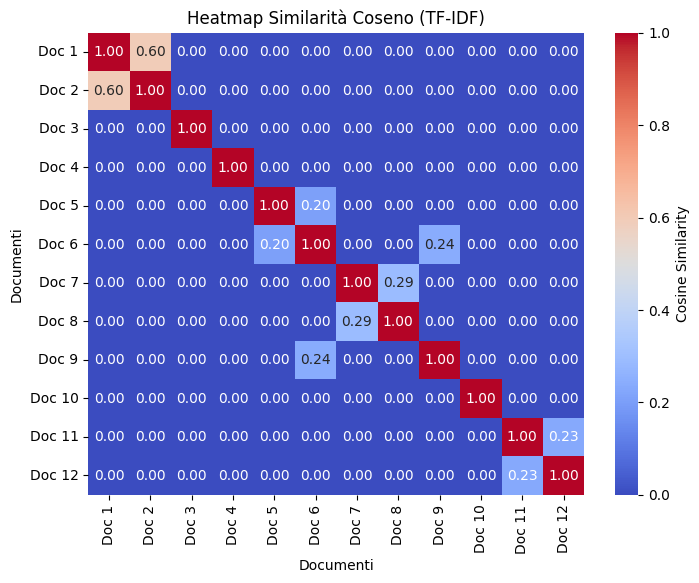

In [2]:
# -----------------------------
# Esempio d'uso
# -----------------------------
documenti_esempio = [
    "Il ristorante era fantastico, il servizio veloce e il cibo ottimo!",
    "Il servizio era lento, ma il cibo era buono.",
    "Non mi è piaciuto il film, la trama era prevedibile.",
    "Film emozionante e ben recitato — lo consiglio!",
    "Ho comprato questo prodotto, ma si è rotto dopo due giorni.",
    "Prodotto eccellente, rapporto qualità-prezzo incredibile.",
    "Il viaggio è stato stancante: ritardi, bagagli persi e caos.",
    "Che bella esperienza di viaggio, tutto perfetto e organizzato.",
    "La qualità del suono è buona, ma le cuffie sono scomode.",
    "Cuffie comode e suono cristallino; molto soddisfatto.",
    "Non ho trovato l'interfaccia intuitiva: difficile da usare.",
    "Interfaccia chiara e molto user-friendly, ottima per principianti."
]

pipeline_tfidf = TfidfPipeline(lingua='italian')
tokens, vocabolario, matrice, similarita = pipeline_tfidf.run_pipeline(documenti_esempio)